In [ ]:
import torch
import platform

print("Python version:", platform.python_version())
print("PyTorch version:", torch.version)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Python version: 3.13.16
PyTorch version: <module 'torch.version' from '/usr/local/lib/python3.13/dist-packages/torch/version.py'>
GPU available: True
GPU name: Tesla T4


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
import pandas as pd

df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

df.head()

Dataset shape: (159571, 8)

Dataset columns:
['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df["comment_text"]
y = df["toxic"]

print("Comments:", len(X))
print("\nLabel distribution:")
print(y.value_counts())

Comments: 159571

Label distribution:
toxic
0    144277
1     15294
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training comments:", len(X_train))
print("Testing comments:", len(X_test))

Training comments: 127656
Testing comments: 31915


In [ ]:
train_sample = pd.concat(
    [
        X_train.rename("comment_text"),
        y_train.rename("toxic")
    ],
    axis=1
)

train_sample = train_sample.sample(
    n=20000,
    random_state=42
)

print("Training sample shape:", train_sample.shape)

print("\nSample label distribution:")
print(train_sample["toxic"].value_counts())

print("\nSample label percentages:")
print(train_sample["toxic"].value_counts(normalize=True) * 100)

Training sample shape: (20000, 2)

Sample label distribution:
toxic
0    18090
1     1910
Name: count, dtype: int64

Sample label percentages:
toxic
0    90.45
1     9.55
Name: proportion, dtype: float64


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("DistilBERT tokenizer loaded successfully.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully.


In [ ]:
sample_text = "You are not a kind person."

tokens = tokenizer.tokenize(sample_text)

token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:", sample_text)
print("\nTokens:", tokens)
print("\nToken IDs:", token_ids)
print("\nNumber of tokens:", len(tokens))

Original text: You are not a kind person.

Tokens: ['you', 'are', 'not', 'a', 'kind', 'person', '.']

Token IDs: [2017, 2024, 2025, 1037, 2785, 2711, 1012]

Number of tokens: 7


In [ ]:
encoded_text = tokenizer(
    sample_text,
    add_special_tokens=True
)

print("Input IDs:", encoded_text["input_ids"])
print("Attention mask:", encoded_text["attention_mask"])

print(
    "Decoded text:",
    tokenizer.decode(encoded_text["input_ids"])
)

Input IDs: [101, 2017, 2024, 2025, 1037, 2785, 2711, 1012, 102]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
Decoded text: [CLS] you are not a kind person. [SEP]


In [ ]:
train_encodings = tokenizer(
    train_sample["comment_text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=128
)

print("Training tokenization completed.")
print("Number of comments:", len(train_encodings["input_ids"]))
print("Tokens per comment:", len(train_encodings["input_ids"][0]))

Training tokenization completed.
Number of comments: 20000
Tokens per comment: 128


In [ ]:
test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding="max_length",
    max_length=128
)

print("Testing tokenization completed.")
print("Number of comments:", len(test_encodings["input_ids"]))
print("Tokens per comment:", len(test_encodings["input_ids"][0]))

Testing tokenization completed.
Number of comments: 31915
Tokens per comment: 128


In [ ]:
print("First comment token IDs:")
print(train_encodings["input_ids"][0])

print("\nFirst comment attention mask:")
print(train_encodings["attention_mask"][0])

print(
    "\nActual tokens:",
    sum(train_encodings["attention_mask"][0])
)

print(
    "Padding tokens:",
    train_encodings["attention_mask"][0].count(0)
)

First comment token IDs:
[101, 1996, 2878, 10778, 2632, 16416, 2094, 2518, 6752, 2229, 2039, 2151, 2224, 1997, 2023, 4431, 2445, 2016, 2038, 2018, 3674, 3441, 1999, 7636, 1999, 1996, 2627, 1012, 2065, 2016, 2359, 2000, 2393, 1996, 2610, 1999, 1996, 2783, 2553, 2016, 2071, 2031, 2445, 10896, 2000, 1996, 2610, 1998, 2074, 2589, 2008, 1012, 2612, 2016, 3632, 2039, 2037, 2007, 10778, 2000, 2079, 1037, 2811, 3034, 1012, 10842, 2296, 19238, 2180, 1005, 1056, 2079, 1010, 1998, 2023, 2028, 2001, 2589, 2011, 1037, 5160, 2025, 1999, 1996, 2457, 1010, 2021, 1037, 5160, 2667, 2000, 17812, 2270, 5448, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First comment attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

In [ ]:
import torch
from torch.utils.data import Dataset

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cu130


In [ ]:
class ToxicCommentDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
train_dataset = ToxicCommentDataset(
    train_encodings,
    train_sample["toxic"].tolist()
)

test_dataset = ToxicCommentDataset(
    test_encodings,
    y_test.tolist()
)

print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

Training dataset size: 20000
Testing dataset size: 31915


In [ ]:
sample = train_dataset[0]

print("Input IDs shape:", sample["input_ids"].shape)
print("Attention mask shape:", sample["attention_mask"].shape)
print("Label:", sample["labels"])

Input IDs shape: torch.Size([128])
Attention mask shape: torch.Size([128])
Label: tensor(0)


In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT classification model loaded successfully.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT classification model loaded successfully.


In [ ]:
print("Number of labels:", model.config.num_labels)
print("Hidden size:", model.config.dim)
print("Number of transformer layers:", model.config.n_layers)
print("Number of attention heads:", model.config.n_heads)

Number of labels: 2
Hidden size: 768
Number of transformer layers: 6
Number of attention heads: 12


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

print("Model device:", device)

Model device: cuda


In [ ]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

Total parameters: 66,955,010
Trainable parameters: 66,955,010


In [ ]:
from transformers import (
    Trainer,
    TrainingArguments
)

print("Training tools imported successfully.")

Training tools imported successfully.


In [ ]:
training_args = TrainingArguments(
    output_dir="./maganor_distilbert",

    num_train_epochs=1,

    per_device_train_batch_size=8,

    learning_rate=2e-5,

    weight_decay=0.01,

    logging_steps=100,

    save_strategy="no",

    eval_strategy="no",

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

print("Training configuration created successfully.")

Training configuration created successfully.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset
)

print("DistilBERT Trainer initialized successfully.")

DistilBERT Trainer initialized successfully.


In [ ]:
training_results = trainer.train()

print("DistilBERT fine-tuning completed.")

Step,Training Loss
100,0.246076
200,0.150407
300,0.216745
400,0.175855
500,0.137729
600,0.162862
700,0.161240
800,0.143160
900,0.174357
1000,0.139596


DistilBERT fine-tuning completed.


In [ ]:
print("Training loss:", training_results.training_loss)

print(
    "Training runtime:",
    training_results.metrics["train_runtime"],
    "seconds"
)

print(
    "Training samples per second:",
    training_results.metrics["train_samples_per_second"]
)

Training loss: 0.14879430770874025
Training runtime: 99.1062 seconds
Training samples per second: 201.804


In [ ]:
import numpy as np

predictions_output = trainer.predict(test_dataset)

logits = predictions_output.predictions

predicted_labels = np.argmax(logits, axis=1)

true_labels = predictions_output.label_ids

print("Number of test comments:", len(true_labels))
print("Number of predictions:", len(predicted_labels))

print("\nFirst 10 actual labels:")
print(true_labels[:10])

print("\nFirst 10 predicted labels:")
print(predicted_labels[:10])

Number of test comments: 31915
Number of predictions: 31915

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted labels:
[0 0 0 0 0 0 0 0 0 1]


In [ ]:
import numpy as np

predictions_output = trainer.predict(test_dataset)

# Extract model predictions
logits = predictions_output.predictions

# Convert logits into predicted class labels
predicted_labels = np.argmax(logits, axis=1)

# Get the actual labels
true_labels = predictions_output.label_ids

print("Number of test comments:", len(true_labels))
print("Number of predictions:", len(predicted_labels))

print("\nFirst 10 actual labels:")
print(true_labels[:10])

print("\nFirst 10 predicted labels:")
print(predicted_labels[:10])

Number of test comments: 31915
Number of predictions: 31915

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted labels:
[0 0 0 0 0 0 0 0 0 1]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(true_labels, predicted_labels)

precision = precision_score(
    true_labels,
    predicted_labels,
    pos_label=1
)

recall = recall_score(
    true_labels,
    predicted_labels,
    pos_label=1
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    pos_label=1
)

print("DistilBERT Evaluation Results")
print("------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=["Non-toxic", "Toxic"],
        zero_division=0
    )
)

DistilBERT Evaluation Results
------------------------------
Accuracy:  0.9668
Precision: 0.8495
Recall:    0.7937
F1-score:  0.8207

Classification Report:
              precision    recall  f1-score   support

   Non-toxic       0.98      0.99      0.98     28856
       Toxic       0.85      0.79      0.82      3059

    accuracy                           0.97     31915
   macro avg       0.91      0.89      0.90     31915
weighted avg       0.97      0.97      0.97     31915



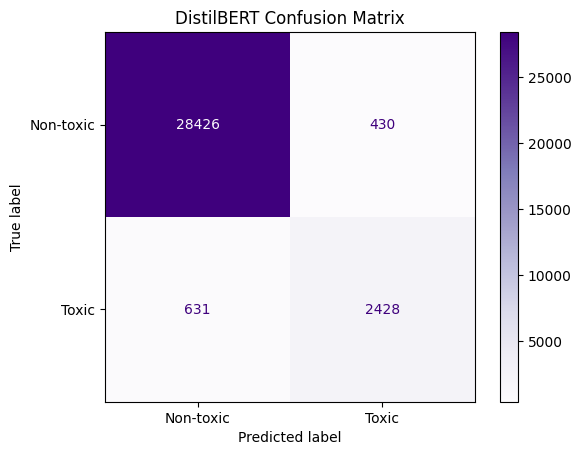

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(true_labels, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-toxic", "Toxic"]
)

display.plot(cmap="Purples", values_format="d")

plt.title("DistilBERT Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(true_labels, predicted_labels)

tn, fp, fn, tp = cm.ravel()

print("DistilBERT Confusion Matrix Results")
print("-----------------------------------")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

DistilBERT Confusion Matrix Results
-----------------------------------
True Negatives: 28426
False Positives: 430
False Negatives: 631
True Positives: 2428


In [ ]:
import pandas as pd

distilbert_results = pd.DataFrame({
    "comment": X_test.values,
    "actual": true_labels,
    "predicted": predicted_labels
}, index=X_test.index)

# Find false negatives
distilbert_fn = distilbert_results[
    (distilbert_results["actual"] == 1) &
    (distilbert_results["predicted"] == 0)
]

print("Total false negatives:", len(distilbert_fn))

print("\nFive examples:")
for index, row in distilbert_fn.head(5).iterrows():
    print("\nIndex:", index)
    print("Comment:", row["comment"])

Total false negatives: 631

Five examples:

Index: 156948
Comment: ")

Trumpet, I certainly will let someone whose posts mainly consist of inaccuracies, insults, ignoring/misrepresenting others views and ""zombies"" tell me how I should refert to this fringe group.
I don't care whether you are a JMer, but the rest of your comment reveals that you have no idea about the historical craft. 
Since you have been explained about Docetism, there's no use in repeating why it and the JesusMyth claim are different. You will not listen.  (smile back) 20:27, 21 March 2006 (UTC"

Index: 137448
Comment: Please look at this guy's talk history. He started it. Yes thats childish but I blame him. I was a good wikipedian before I met him. he sucks. He adds nothing, just vandalises stuff, and was rude to me -check my page history. He should clearly be kicked off wikipedia. P.S., I know igonorance is not a crime, but we have to draw the line somewhere.

Index: 1653
Comment: No silly it isnt ITS UR MOMS and

In [ ]:
import torch

# Convert model logits into probabilities
probabilities = torch.softmax(
    torch.tensor(logits),
    dim=1
).numpy()

# Probability that each comment is toxic
distilbert_results["toxic_probability"] = probabilities[:, 1]

# Add comment length
distilbert_results["comment_length"] = (
    distilbert_results["comment"].str.len()
)

# Extract false negatives with their probabilities
distilbert_fn = distilbert_results[
    (distilbert_results["actual"] == 1) &
    (distilbert_results["predicted"] == 0)
].copy()

print("False-negative probability statistics:")
print(distilbert_fn["toxic_probability"].describe())

print("\nFive most confident mistakes:")
print(
    distilbert_fn.sort_values(
        "toxic_probability"
    ).head(5)[
        ["comment", "toxic_probability", "comment_length"]
    ].to_string(index=False)
)

False-negative probability statistics:
count    631.000000
mean       0.078701
std        0.116733
min        0.000543
25%        0.006339
50%        0.022138
75%        0.099581
max        0.492833
Name: toxic_probability, dtype: float64

Five most confident mistakes:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [ ]:
# Compare comment lengths

print("False-negative comment lengths:")
print(distilbert_fn["comment_length"].describe())

print("\nCorrectly identified toxic comment lengths:")
true_positives = distilbert_results[
    (distilbert_results["actual"] == 1) &
    (distilbert_results["predicted"] == 1)
]

print(true_positives["comment"].str.len().describe())

False-negative comment lengths:
count     631.000000
mean      408.313788
std       721.205670
min        19.000000
25%        80.500000
50%       167.000000
75%       423.000000
max      5000.000000
Name: comment_length, dtype: float64

Correctly identified toxic comment lengths:
count    2428.000000
mean      268.547776
std       593.723834
min         8.000000
25%        55.000000
50%       111.000000
75%       238.250000
max      5000.000000
Name: comment, dtype: float64


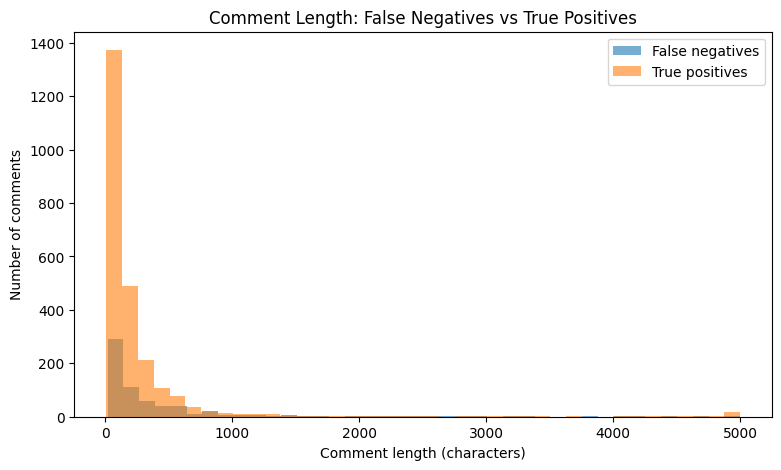

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(
    distilbert_fn["comment_length"],
    bins=40,
    alpha=0.6,
    label="False negatives"
)

plt.hist(
    true_positives["comment"].str.len(),
    bins=40,
    alpha=0.6,
    label="True positives"
)

plt.xlabel("Comment length (characters)")
plt.ylabel("Number of comments")
plt.title("Comment Length: False Negatives vs True Positives")
plt.legend()
plt.show()

In [ ]:
# Calculate token lengths before truncation

fn_comments = distilbert_fn["comment"].tolist()

fn_token_lengths = [
    len(tokenizer(
        comment,
        truncation=False,
        add_special_tokens=True
    )["input_ids"])
    for comment in fn_comments
]

print("Total false-negative comments:", len(fn_token_lengths))

print(
    "Comments exceeding 128 tokens:",
    sum(length > 128 for length in fn_token_lengths)
)

print(
    "Percentage exceeding 128 tokens:",
    round(
        sum(length > 128 for length in fn_token_lengths)
        / len(fn_token_lengths) * 100,
        2
    ),
    "%"
)

print("\nToken length statistics:")
print(pd.Series(fn_token_lengths).describe())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (813 > 512). Running this sequence through the model will result in indexing errors


Total false-negative comments: 631
Comments exceeding 128 tokens: 131
Percentage exceeding 128 tokens: 20.76 %

Token length statistics:
count     631.000000
mean      103.458003
std       191.787236
min         6.000000
25%        23.000000
50%        44.000000
75%       110.500000
max      2275.000000
dtype: float64


In [ ]:
max_length=128

In [ ]:
# Create a DataFrame containing all actual toxic test comments
toxic_test = pd.DataFrame({
    "actual": true_labels,
    "predicted": predicted_labels
}, index=X_test.index)

toxic_test = toxic_test[toxic_test["actual"] == 1].copy()

# Calculate original token length for every toxic test comment
toxic_test["token_length"] = [
    len(tokenizer(
        comment,
        truncation=False,
        add_special_tokens=True
    )["input_ids"])
    for comment in X_test.loc[toxic_test.index]
]

# Identify comments that were missed
toxic_test["missed"] = (
    toxic_test["predicted"] == 0
)

# Group comments by the 128-token limit
toxic_test["length_group"] = toxic_test[
    "token_length"
].apply(
    lambda length: "Over 128 tokens"
    if length > 128 else "128 tokens or fewer"
)

# Calculate false-negative rates
length_analysis = toxic_test.groupby(
    "length_group"
).agg(
    total_comments=("missed", "count"),
    missed_comments=("missed", "sum"),
    false_negative_rate=("missed", "mean")
)

length_analysis["false_negative_rate"] *= 100

print(length_analysis)

                     total_comments  missed_comments  false_negative_rate
length_group                                                             
128 tokens or fewer            2675              500            18.691589
Over 128 tokens                 384              131            34.114583


In [ ]:
from scipy.stats import chi2_contingency

# Rows: short comments, long comments
# Columns: correctly identified, missed
contingency_table = [
    [2675 - 500, 500],
    [384 - 131, 131]
]

chi2, p_value, degrees_of_freedom, expected = (
    chi2_contingency(contingency_table)
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)

if p_value < 0.05:
    print("\nThe association is statistically significant.")
else:
    print("\nThe association is not statistically significant.")

Chi-square statistic: 47.84839776270838
P-value: 4.6048324385249015e-12
Degrees of freedom: 1

The association is statistically significant.


In [ ]:
# Tokenize training comments with 256 tokens
train_encodings_256 = tokenizer(
    train_sample["comment_text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=256
)

# Tokenize test comments with 256 tokens
test_encodings_256 = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding="max_length",
    max_length=256
)

print("Training examples:", len(train_encodings_256["input_ids"]))
print("Testing examples:", len(test_encodings_256["input_ids"]))

print("Training sequence shape:",
      len(train_encodings_256["input_ids"][0]))

print("Testing sequence shape:",
      len(test_encodings_256["input_ids"][0]))

Training examples: 20000
Testing examples: 31915
Training sequence shape: 256
Testing sequence shape: 256


In [ ]:
from transformers import AutoModelForSequenceClassification

# Load a fresh pretrained DistilBERT model
model_256 = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("Fresh DistilBERT model loaded successfully.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT model loaded successfully.


In [ ]:
from transformers import TrainingArguments, Trainer
import torch

training_args_256 = TrainingArguments(
    output_dir="./maganor_distilbert_256",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="no",
    eval_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)

trainer_256 = Trainer(
    model=model_256,
    args=training_args_256,
    train_dataset=train_dataset_256
)

print("256-token training configuration is ready.")

NameError: name 'train_dataset_256' is not defined

In [ ]:
# Create the 256-token training dataset
train_dataset_256 = ToxicCommentDataset(
    train_encodings_256,
    train_sample["toxic"].tolist()
)

# Create the 256-token testing dataset
test_dataset_256 = ToxicCommentDataset(
    test_encodings_256,
    y_test.tolist()
)

print("Training dataset:", len(train_dataset_256))
print("Testing dataset:", len(test_dataset_256))

print("Input shape:", train_dataset_256[0]["input_ids"].shape)
print("Attention mask shape:", train_dataset_256[0]["attention_mask"].shape)

Training dataset: 20000
Testing dataset: 31915
Input shape: torch.Size([256])
Attention mask shape: torch.Size([256])


In [ ]:
# Train the 256-token DistilBERT model
training_results_256 = trainer_256.train()

print("\nTraining completed!")

print("Training loss:", training_results_256.training_loss)

print(
    "Training runtime:",
    training_results_256.metrics["train_runtime"],
    "seconds"
)

print(
    "Training samples per second:",
    training_results_256.metrics["train_samples_per_second"]
)

NameError: name 'trainer_256' is not defined

In [ ]:
from transformers import TrainingArguments, Trainer
import torch

training_args_256 = TrainingArguments(
    output_dir="./maganor_distilbert_256",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="no",
    eval_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)

trainer_256 = Trainer(
    model=model_256,
    args=training_args_256,
    train_dataset=train_dataset_256
)

print("Trainer created successfully!")

Trainer created successfully!


In [ ]:
training_results_256 = trainer_256.train()

print("\nTraining completed!")

print("Training loss:", training_results_256.training_loss)

print(
    "Training runtime:",
    training_results_256.metrics["train_runtime"],
    "seconds"
)

print(
    "Training samples per second:",
    training_results_256.metrics["train_samples_per_second"]
)

Step,Training Loss
100,0.226719
200,0.144254
300,0.220976
400,0.172873
500,0.156863
600,0.156427
700,0.142145
800,0.162230
900,0.141737
1000,0.145896



Training completed!
Training loss: 0.14793958778381347
Training runtime: 146.5791 seconds
Training samples per second: 136.445


In [ ]:
# Generate predictions on the test dataset
predictions_256 = trainer_256.predict(test_dataset_256)

# Extract model predictions
logits_256 = predictions_256.predictions

y_pred_256 = np.argmax(logits_256, axis=1)

# Actual labels
y_true_256 = predictions_256.label_ids

print("Predictions generated:", len(y_pred_256))
print("Actual labels:", len(y_true_256))

Predictions generated: 31915
Actual labels: 31915


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_256 = accuracy_score(y_true_256, y_pred_256)
precision_256 = precision_score(y_true_256, y_pred_256)
recall_256 = recall_score(y_true_256, y_pred_256)
f1_256 = f1_score(y_true_256, y_pred_256)

print("256-Token DistilBERT Evaluation")
print("--------------------------------")
print(f"Accuracy:  {accuracy_256:.4f}")
print(f"Precision: {precision_256:.4f}")
print(f"Recall:    {recall_256:.4f}")
print(f"F1-score:  {f1_256:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_true_256,
        y_pred_256,
        target_names=["Non-toxic", "Toxic"]
    )
)

256-Token DistilBERT Evaluation
--------------------------------
Accuracy:  0.9664
Precision: 0.8476
Recall:    0.7924
F1-score:  0.8191

Detailed Classification Report:
              precision    recall  f1-score   support

   Non-toxic       0.98      0.98      0.98     28856
       Toxic       0.85      0.79      0.82      3059

    accuracy                           0.97     31915
   macro avg       0.91      0.89      0.90     31915
weighted avg       0.97      0.97      0.97     31915



256-Token Confusion Matrix:
[[28420   436]
 [  635  2424]]


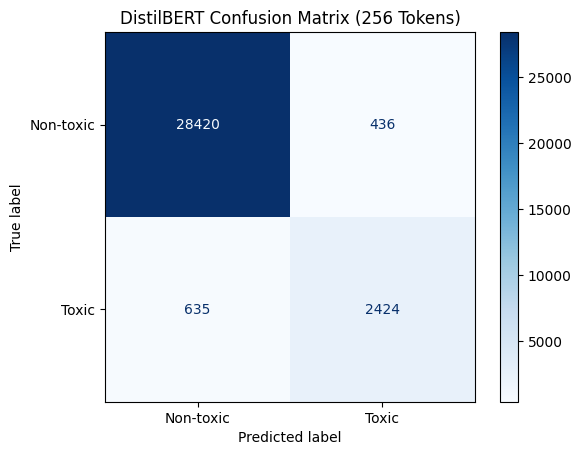

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_256 = confusion_matrix(y_true_256, y_pred_256)

print("256-Token Confusion Matrix:")
print(cm_256)

# Visualize the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_256,
    display_labels=["Non-toxic", "Toxic"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT Confusion Matrix (256 Tokens)")
plt.show()

In [ ]:
# Calculate token lengths for all test comments
test_token_lengths = tokenizer(
    X_test.tolist(),
    truncation=False,
    padding=False
)["input_ids"]

# Create a results DataFrame
results_256 = pd.DataFrame({
    "comment": X_test.tolist(),
    "actual": y_true_256,
    "predicted": y_pred_256,
    "token_length": [len(tokens) for tokens in test_token_lengths]
})

# Select genuinely toxic comments
toxic_comments_256 = results_256[
    results_256["actual"] == 1
].copy()

# Group by token length
toxic_comments_256["length_group"] = np.where(
    toxic_comments_256["token_length"] > 256,
    "Over 256 tokens",
    "256 tokens or fewer"
)

# Calculate false-negative rates
length_analysis_256 = toxic_comments_256.groupby(
    "length_group"
).agg(
    total_comments=("actual", "count"),
    missed_comments=("predicted", lambda x: (x == 0).sum())
)

length_analysis_256["false_negative_rate"] = (
    length_analysis_256["missed_comments"]
    / length_analysis_256["total_comments"]
    * 100
)

print(length_analysis_256)

                     total_comments  missed_comments  false_negative_rate
length_group                                                             
256 tokens or fewer            2915              586            20.102916
Over 256 tokens                 144               49            34.027778


In [ ]:
from scipy.stats import chi2_contingency
import numpy as np

# Construct the contingency table
# Rows: shorter and longer comments
# Columns: missed and correctly identified toxic comments

contingency_table_256 = np.array([
    [586, 2329],
    [49, 95]
])

chi2_256, p_value_256, dof_256, expected_256 = (
    chi2_contingency(contingency_table_256)
)

# Calculate Cramér's V
cramers_v_256 = np.sqrt(chi2_256 / contingency_table_256.sum())

print("Chi-square statistic:", chi2_256)
print("P-value:", p_value_256)
print("Degrees of freedom:", dof_256)
print("Cramér's V:", cramers_v_256)

if p_value_256 < 0.05:
    print("\nThe association is statistically significant.")
else:
    print("\nThe association is not statistically significant.")

Chi-square statistic: 15.339978723957476
P-value: 8.979596574560946e-05
Degrees of freedom: 1
Cramér's V: 0.07081457289668472

The association is statistically significant.


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "DistilBERT (128 tokens)",
        "DistilBERT (256 tokens)"
    ],
    "Accuracy": [
        0.9404,
        accuracy_128 if "accuracy_128" in globals() else 0.9668,
        accuracy_256
    ],
    "Precision": [
        0.6407,
        precision_128 if "precision_128" in globals() else 0.8495,
        precision_256
    ],
    "Recall": [
        0.8604,
        recall_128 if "recall_128" in globals() else 0.7937,
        recall_256
    ],
    "F1-score": [
        0.7345,
        f1_128 if "f1_128" in globals() else 0.8207,
        f1_256
    ]
})

print("FINAL MODEL COMPARISON")
display(comparison.round(4))

FINAL MODEL COMPARISON


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
from IPython.display import display as show_table

print("FINAL MODEL COMPARISON")
show_table(comparison.round(4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score
0,TF-IDF + Logistic Regression,0.9404,0.6407,0.8604,0.7345
1,DistilBERT (128 tokens),0.9668,0.8495,0.7937,0.8207
2,DistilBERT (256 tokens),0.9664,0.8476,0.7924,0.8191


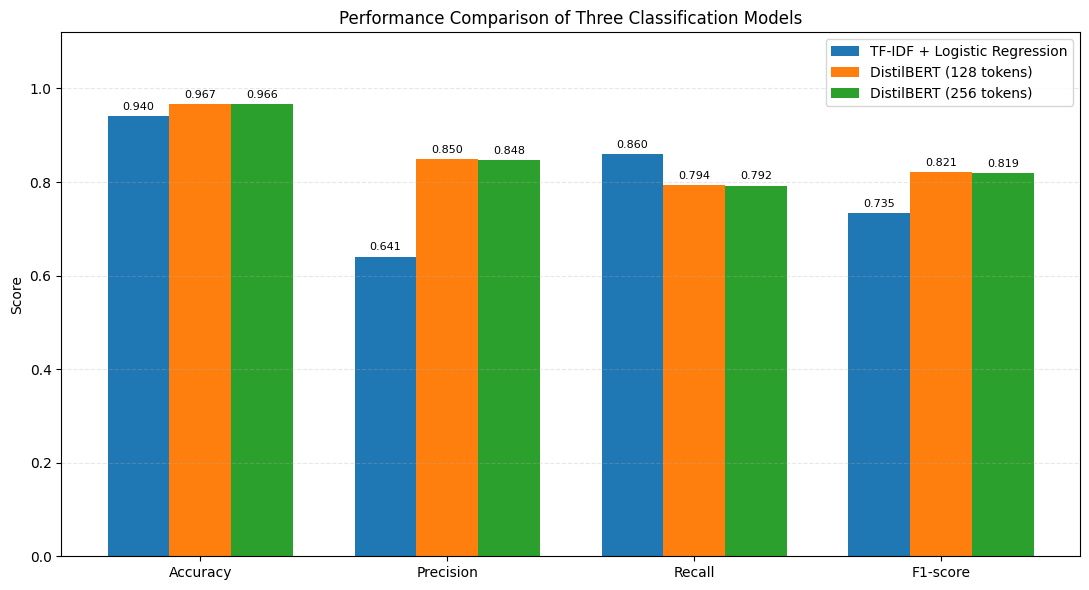

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(11, 6))

for i, model_name in enumerate(comparison["Model"]):
    values = comparison.loc[i, metrics].values.astype(float)

    bars = plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=model_name
    )

    plt.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Performance Comparison of Three Classification Models")
plt.ylim(0, 1.12)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Save the final model comparison as a CSV file
comparison.to_csv(
    "maganor_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [ ]:
from google.colab import files

files.download("maganor_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>